In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

In [38]:
start = '2012-01-01'
end = '2025-01-01'
stock = 'GOOG'

data = yf.download(stock, start, end)

[*********************100%***********************]  1 of 1 completed


In [39]:
data.reset_index(inplace=True)

In [40]:
data

Price,Date,Close,High,Low,Open,Volume
Ticker,,GOOG,GOOG,GOOG,GOOG,GOOG
0,2012-01-03,16.417627,16.485232,16.095891,16.109956,147611217
1,2012-01-04,16.488441,16.537048,16.299447,16.408255,114989399
2,2012-01-05,16.259722,16.382100,16.191131,16.336702,131808205
3,2012-01-06,16.037912,16.284148,16.032236,16.263175,108119746
4,2012-01-09,15.357925,15.963400,15.327577,15.951062,233776981
...,...,...,...,...,...,...
3265,2024-12-24,196.419449,196.518857,194.061253,195.027593,6809800
3266,2024-12-26,195.952209,197.006034,194.729361,195.594305,7907900
3267,2024-12-27,192.910019,195.653956,190.854069,195.325876,14693000


In [41]:
mavg_100_days = data.Close.rolling(100).mean()

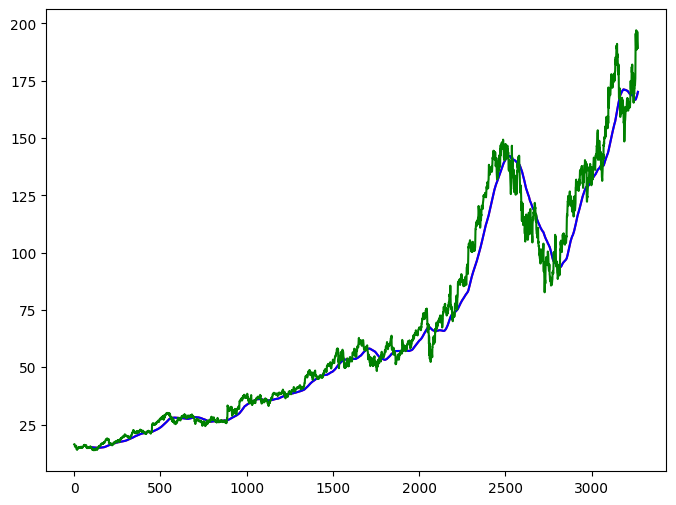

In [42]:
plt.figure(figsize=(8,6))
plt.plot(mavg_100_days, 'r')
plt.plot(mavg_100_days, 'b')
plt.plot(data.Close, 'g')
plt.show()

In [43]:
mavg_200_days = data.Close.rolling(200).mean()

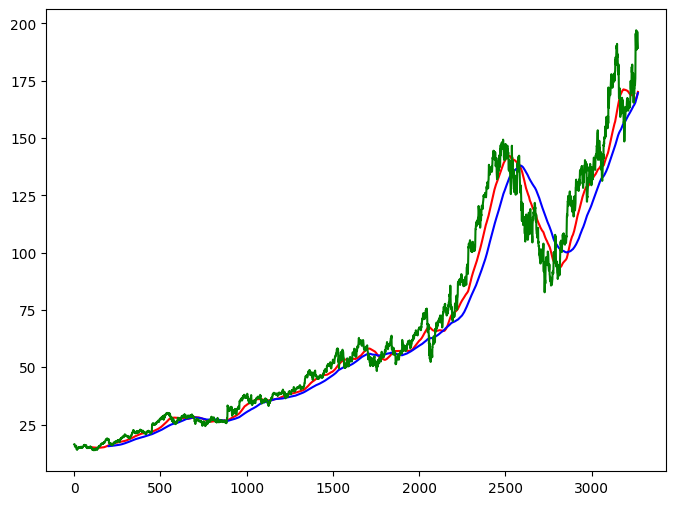

In [44]:
plt.figure(figsize=(8,6))
plt.plot(mavg_100_days, 'r')
plt.plot(mavg_200_days, 'b')
plt.plot(data.Close, 'g')
plt.show()

In [45]:
data.dropna(inplace=True)

In [46]:
data_train = pd.DataFrame(data.Close[0: int(len(data)*0.80)])
data_test = pd.DataFrame(data.Close[int(len(data)*0.80): len(data)])

In [47]:
data_train.shape[0]

2616

In [48]:
data_test.shape[0]

654

In [49]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0, 1))

In [50]:
data_train_scale = scaler.fit_transform(data_train)

In [51]:
x = []
y =[]

for i in range(100, data_train_scale.shape[0]):
    x.append(data_train_scale[i-100:i])
    y.append(data_train_scale[i,0])

In [52]:
x, y = np.array(x), np.array(y)

In [53]:
from tensorflow.keras.layers import Dense, Dropout, LSTM, Input
from tensorflow.keras.models import Sequential

In [57]:
model = Sequential()
model.add(Input(shape=(x_train.shape[1], 1)))
model.add(LSTM(units = 50, activation = 'relu', return_sequences = True, input_shape = ((x.shape[1],1))))
model.add(Dropout(0.2))

model.add(LSTM(units = 60, activation= 'relu', return_sequences = True))
model.add(Dropout(0.3))

model.add(LSTM(units = 80, activation = 'relu', return_sequences = True))
model.add(Dropout(0.4))

model.add(LSTM(units = 120, activation = 'relu'))
model.add(Dropout(0.5))

model.add(Dense(units= 1))

NameError: name 'x_train' is not defined

In [55]:
model.compile(optimizer = 'adam', loss = 'mean_squared_error')

In [56]:
model.fit(x,y, epochs = 50, batch_size = 32, verbose = 1)

Epoch 1/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 27s 237ms/step - loss: 0.0205
Epoch 2/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 19s 237ms/step - loss: 0.0051
Epoch 3/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 19s 236ms/step - loss: 0.0041
Epoch 4/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 18s 233ms/step - loss: 0.0043
Epoch 5/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 19s 235ms/step - loss: 0.0035
Epoch 6/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 19s 235ms/step - loss: 0.0039
Epoch 7/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 21s 261ms/step - loss: 0.0035
Epoch 8/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 19s 239ms/step - loss: 0.0038
Epoch 9/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 19s 235ms/step - loss: 0.0035
Epoch 10/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 19s 236ms/step - loss: 0.0032
Epoch 11/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 19s 235ms/step - loss: 0.0033
Epoch 12/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 19s 237ms/step - loss: 0.0028
Epoch 13/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 19s 236ms/step - loss: 0.0032
Epoch 14/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 19s 234ms/step - loss: 0.0029
Epoch 15/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 19s 